In [ ]:
import pandas as pd

# Load Data

In [ ]:
# data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\tonghopdata.csv')

data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\GSE183635_TEP_Count_Matrix.csv')
# name_gene =  pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\183635\Human_CH38p13annot.csv', low_memory=False    )


In [ ]:
data

,Unnamed: 0,1-Vumc-HD-101-TR922,2-Vumc-HD-103-TR923,3-Vumc-HD-108-TR924,4-Vumc-HD-127-TR925,5-Vumc-HD-130-TR926,6-Vumc-HD-142-TR927,7-Vumc-HD-143-TR928,8-Vumc-HD-144-TR929,9-Vumc-HD-145-TR930,...,countMatrix.3502-NKI-4854-SARC-TR3080,countMatrix.3503-NKI-4707-SARC-TR3079,countMatrix.3504-NKI-4941-SARC-TR3084,countMatrix.3507-NKI-6348-SARC-TR3134,countMatrix.3508-NKI-5275-SARC-TR3099,countMatrix.3512-NKI-5148-SARC-TR3129,countMatrix.320-10,countMatrix.327-34,countMatrix.376-P-PH-001-013-TR1400,countMatrix.506-NKI-NSCLC-107-270
0,ENSG00000000419,5,79,58,128,93,12,0,0,18,...,3,0,1,2,9,16,22,21,0,1
1,ENSG00000000460,8,10,21,14,6,8,25,42,5,...,0,3,0,2,63,3,3,0,1,0
2,ENSG00000000938,24,336,334,59,120,22,31,13,19,...,8,45,1,7,163,90,46,75,14,8
3,ENSG00000001036,38,46,15,36,25,43,27,27,59,...,1,3,4,15,3,6,10,8,3,0
4,ENSG00000001461,72,17,11,9,18,28,5,6,49,...,1,1,0,0,12,2,6,6,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5435,ENSG00000271043,349,133,99,87,171,260,232,204,188,...,0,0,0,5,0,2,18,31,22,23
5436,ENSG00000272053,980,658,294,265,818,2066,1579,1161,2003,...,18,17,17,107,41,52,78,203,12,16
5437,ENSG00000272168,51,20,11,31,65,49,56,25,131,...,0,0,0,26,0,1,15,6,10,0
5438,ENSG00000272369,29,41,24,3,51,33,26,52,35,...,0,3,1,8,2,1,0,3,2,1


In [ ]:
import numpy as np

# Minimal TMM normalization adapted from edgeR logic
# Returns CPM and factors scaled so geometric mean of factors is 1.
def compute_tmm_cpm(counts_df, trim_M=0.3, trim_A=0.05, ref_sample=None):
    counts = counts_df.copy()
    lib_sizes = counts.sum(axis=0)

    # Pick reference sample: closest library size to median if none provided
    if ref_sample is None:
        ref_sample = (lib_sizes - lib_sizes.median()).abs().idxmin()
    ref_counts = counts[ref_sample]
    lib_ref = lib_sizes[ref_sample]

    factors = {}

    def tmm_factor(test_counts, lib_test):
        mask = (test_counts > 0) & (ref_counts > 0)
        if mask.sum() == 0:
            return 1.0

        test = test_counts[mask]
        ref = ref_counts[mask]

        logR = np.log2((test / lib_test) / (ref / lib_ref))
        logA = 0.5 * np.log2((test / lib_test) * (ref / lib_ref))
        weights = 1.0 / ((1.0 / test) + (1.0 / ref))

        # Trim extremes on M and A
        m_low, m_high = np.quantile(logR, [trim_M / 2, 1 - trim_M / 2])
        a_low, a_high = np.quantile(logA, [trim_A / 2, 1 - trim_A / 2])
        keep = (logR >= m_low) & (logR <= m_high) & (logA >= a_low) & (logA <= a_high)

        if keep.sum() == 0:
            return 1.0

        weighted_M = np.average(logR[keep], weights=weights[keep])
        return 2 ** weighted_M

    for col in counts.columns:
        factors[col] = tmm_factor(counts[col], lib_sizes[col])

    factors = pd.Series(factors)
    factors = factors / np.exp(np.log(factors).mean())  # rescale to geometric mean 1
    effective_lib_sizes = lib_sizes * factors

    cpm = counts.divide(effective_lib_sizes, axis=1) * 1_000_000
    return cpm, factors, effective_lib_sizes

In [ ]:
# Apply TMM normalization → CPM → log2(CPM+1)
count_cols = data.columns.drop('Unnamed: 0')
counts_numeric = data[count_cols].apply(pd.to_numeric, errors='coerce').fillna(0)

# TMM factors trimmed at 30% for M and 5% for A (edgeR defaults)
tmm_cpm, tmm_factors, tmm_libsizes = compute_tmm_cpm(
    counts_numeric,
    trim_M=0.3,
    trim_A=0.05,
)

tmm_log2 = np.log2(tmm_cpm + 1)

# Reattach gene column and use the normalized values for downstream steps
tmm_log2.insert(0, 'Unnamed: 0', data['Unnamed: 0'])
raw_counts = data.copy()
data = tmm_log2

tmm_log2.head()

,Unnamed: 0,1-Vumc-HD-101-TR922,2-Vumc-HD-103-TR923,3-Vumc-HD-108-TR924,4-Vumc-HD-127-TR925,5-Vumc-HD-130-TR926,6-Vumc-HD-142-TR927,7-Vumc-HD-143-TR928,8-Vumc-HD-144-TR929,9-Vumc-HD-145-TR930,...,countMatrix.3502-NKI-4854-SARC-TR3080,countMatrix.3503-NKI-4707-SARC-TR3079,countMatrix.3504-NKI-4941-SARC-TR3084,countMatrix.3507-NKI-6348-SARC-TR3134,countMatrix.3508-NKI-5275-SARC-TR3099,countMatrix.3512-NKI-5148-SARC-TR3129,countMatrix.320-10,countMatrix.327-34,countMatrix.376-P-PH-001-013-TR1400,countMatrix.506-NKI-NSCLC-107-270
0,ENSG00000000419,2.017623,5.475091,5.512604,7.068203,6.576647,3.440432,0.000000,0.000000,3.805785,...,5.433418,0.000000,3.812156,2.854691,3.997977,5.492312,5.696897,5.803840,0.000000,3.505437
1,ENSG00000000460,2.555486,2.701288,4.101573,3.960546,2.826485,2.920431,4.470578,5.605382,2.203791,...,0.000000,4.384776,0.000000,2.854691,6.725782,3.209872,2.988622,0.000000,2.795403,0.000000
2,ENSG00000000938,3.966797,7.538603,8.011974,5.963365,6.940974,4.253194,4.768268,3.978141,3.878348,...,6.827438,8.225726,3.812156,4.512050,8.088844,7.957569,6.746443,7.621626,6.395603,6.389763
3,ENSG00000001036,4.595362,4.717955,3.649376,5.265344,4.721882,5.182598,4.576781,4.984322,5.444972,...,3.913727,4.384776,5.732993,5.577463,2.583164,4.129725,4.592388,4.452889,4.234712,0.000000
4,ENSG00000001461,5.488898,3.372464,3.243132,3.373701,4.269056,4.584814,2.387949,2.965698,5.183782,...,3.913727,2.931715,0.000000,0.000000,4.390262,2.700837,3.894751,4.059645,2.795403,0.000000


In [ ]:
data

,Unnamed: 0,1-Vumc-HD-101-TR922,2-Vumc-HD-103-TR923,3-Vumc-HD-108-TR924,4-Vumc-HD-127-TR925,5-Vumc-HD-130-TR926,6-Vumc-HD-142-TR927,7-Vumc-HD-143-TR928,8-Vumc-HD-144-TR929,9-Vumc-HD-145-TR930,...,countMatrix.3502-NKI-4854-SARC-TR3080,countMatrix.3503-NKI-4707-SARC-TR3079,countMatrix.3504-NKI-4941-SARC-TR3084,countMatrix.3507-NKI-6348-SARC-TR3134,countMatrix.3508-NKI-5275-SARC-TR3099,countMatrix.3512-NKI-5148-SARC-TR3129,countMatrix.320-10,countMatrix.327-34,countMatrix.376-P-PH-001-013-TR1400,countMatrix.506-NKI-NSCLC-107-270
0,ENSG00000000419,2.017623,5.475091,5.512604,7.068203,6.576647,3.440432,0.000000,0.000000,3.805785,...,5.433418,0.000000,3.812156,2.854691,3.997977,5.492312,5.696897,5.803840,0.000000,3.505437
1,ENSG00000000460,2.555486,2.701288,4.101573,3.960546,2.826485,2.920431,4.470578,5.605382,2.203791,...,0.000000,4.384776,0.000000,2.854691,6.725782,3.209872,2.988622,0.000000,2.795403,0.000000
2,ENSG00000000938,3.966797,7.538603,8.011974,5.963365,6.940974,4.253194,4.768268,3.978141,3.878348,...,6.827438,8.225726,3.812156,4.512050,8.088844,7.957569,6.746443,7.621626,6.395603,6.389763
3,ENSG00000001036,4.595362,4.717955,3.649376,5.265344,4.721882,5.182598,4.576781,4.984322,5.444972,...,3.913727,4.384776,5.732993,5.577463,2.583164,4.129725,4.592388,4.452889,4.234712,0.000000
4,ENSG00000001461,5.488898,3.372464,3.243132,3.373701,4.269056,4.584814,2.387949,2.965698,5.183782,...,3.913727,2.931715,0.000000,0.000000,4.390262,2.700837,3.894751,4.059645,2.795403,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5435,ENSG00000271043,7.740330,6.213363,6.270833,6.516204,7.448430,7.745160,7.625442,7.861764,7.094012,...,0.000000,0.000000,0.000000,4.051695,0.000000,2.700837,5.413558,6.357364,7.041435,7.902060
5436,ENSG00000272053,9.225534,8.504428,7.828702,8.112483,9.699986,10.729526,10.386010,10.365369,10.497769,...,7.990288,6.829252,7.799562,8.385825,6.113350,7.170391,7.502760,9.053517,6.176063,7.381134
5437,ENSG00000272168,5.004566,3.585881,3.243132,5.055652,6.066353,5.366171,5.597597,4.876933,6.577433,...,0.000000,0.000000,0.000000,6.358173,0.000000,1.907235,5.157277,4.059645,5.917014,0.000000
5438,ENSG00000272369,4.223819,4.558615,4.283675,2.043272,5.722308,4.812715,4.524657,5.907795,4.714145,...,0.000000,4.384776,3.812156,4.696769,2.113817,1.907235,0.000000,3.143667,3.687565,3.505437


In [ ]:
data.drop_duplicates(inplace=True)

In [ ]:
# Transpose so samples become rows
data_transposed = data.set_index('Unnamed: 0').T
data_transposed

Unnamed: 0,ENSG00000000419,ENSG00000000460,ENSG00000000938,ENSG00000001036,ENSG00000001461,ENSG00000001497,ENSG00000001629,ENSG00000001631,ENSG00000002330,ENSG00000002549,...,ENSG00000267279,ENSG00000267316,ENSG00000268555,ENSG00000269028,ENSG00000270055,ENSG00000271043,ENSG00000272053,ENSG00000272168,ENSG00000272369,ENSG00000272888
1-Vumc-HD-101-TR922,2.017623,2.555486,3.966797,4.595362,5.488898,2.827478,4.766742,4.175947,5.004566,5.387457,...,6.114808,7.398349,7.244397,9.104490,5.300835,7.740330,9.225534,5.004566,4.223819,4.976895
2-Vumc-HD-103-TR923,5.475091,2.701288,7.538603,4.717955,3.372464,4.524521,3.585881,5.720714,4.558615,5.836403,...,5.594933,5.850234,5.264011,7.730278,3.447167,6.213363,8.504428,3.585881,4.558615,5.156804
3-Vumc-HD-108-TR924,5.512604,4.101573,8.011974,3.649376,3.243132,3.355909,6.212118,4.843733,3.649376,6.241774,...,4.636085,5.331380,5.186406,7.537348,2.675596,6.270833,7.828702,3.243132,4.283675,4.843733
4-Vumc-HD-127-TR925,7.068203,3.960546,5.963365,5.265344,3.373701,3.860741,4.224207,5.413591,4.810214,5.448389,...,5.728734,5.641202,4.699015,8.342634,3.373701,6.516204,8.112483,5.055652,2.043272,4.447047
5-Vumc-HD-130-TR926,6.576647,2.826485,6.940974,4.721882,4.269056,3.342008,4.190989,5.694285,5.269639,6.790275,...,6.231448,7.316774,5.999222,9.370988,4.480719,7.448430,9.699986,6.066353,5.722308,5.545375
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
countMatrix.3512-NKI-5148-SARC-TR3129,5.492312,3.209872,7.957569,4.129725,2.700837,5.577888,5.087918,5.087918,3.209872,5.735170,...,4.833343,4.340296,4.340296,3.585392,3.209872,2.700837,7.170391,1.907235,1.907235,4.129725
countMatrix.320-10,5.696897,2.988622,6.746443,4.592388,3.894751,0.000000,5.333085,3.650986,3.357487,6.473635,...,4.724445,5.877980,5.060626,7.196531,4.103220,5.413558,7.502760,5.157277,0.000000,6.836768
countMatrix.327-34,5.803840,0.000000,7.621626,4.452889,4.059645,2.638101,5.419570,3.813811,4.761582,6.857391,...,3.813811,4.615476,6.570646,7.801336,1.853021,6.357364,9.053517,4.059645,3.143667,6.160659
countMatrix.376-P-PH-001-013-TR1400,0.000000,2.795403,6.395603,4.234712,2.795403,3.687565,4.940695,4.630464,3.687565,0.000000,...,2.795403,4.940695,6.052345,6.905026,3.687565,7.041435,6.176063,5.917014,3.687565,4.940695


In [ ]:
# data_transposed.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\otherdata can be merged\raw.csv', index=True )

In [ ]:
data_transposed['cancer_type'] = (
    data_transposed['cancer_type']
    .replace('Other/Unknown', 'Asymptomatic_Controls')
)


In [ ]:
data_transposed['cancer_type'].value_counts()

cancer_type
NSCLC                    533
Asymptomatic_Controls    337
Symptomatic_Control      228
Ovarian                  176
Pancreas                 170
Kidney_Renal             117
Prostate_Bladder         105
Head_Neck                 98
Glioblastoma              93
Hepatobiliary             92
Breast                    87
Colorectal                65
Sarcoma                   62
Melanoma                  45
Low_Grade_Glioma          41
Multiple_Myeloma          30
brain_metastasis          23
Lymphoma                  20
Gastric                   15
Esophageal                14
Name: count, dtype: int64

In [ ]:
# Extract the names of the remaining 338
remaining_unknowns = [c for c in data.columns if categorize_tumor_type(c) == 'Other/Unknown']

# Look for patterns

print(pd.Series(remaining_unknowns).head(44))

0    countMatrix.320-10
1    countMatrix.327-34
dtype: object


In [ ]:
data_transposed = data_transposed[
    data_transposed['cancer_type'] != 'Symptomatic_Control'
]

In [ ]:
data_transposed.reset_index(drop=True, inplace=True)


In [ ]:
data_transposed

Unnamed: 0,ENSG00000000419,ENSG00000000460,ENSG00000000938,ENSG00000001036,ENSG00000001461,ENSG00000001497,ENSG00000001629,ENSG00000001631,ENSG00000002330,ENSG00000002549,...,ENSG00000267316,ENSG00000268555,ENSG00000269028,ENSG00000270055,ENSG00000271043,ENSG00000272053,ENSG00000272168,ENSG00000272369,ENSG00000272888,cancer_type
0,2.017623,2.555486,3.966797,4.595362,5.488898,2.827478,4.766742,4.175947,5.004566,5.387457,...,7.398349,7.244397,9.104490,5.300835,7.740330,9.225534,5.004566,4.223819,4.976895,Asymptomatic_Controls
1,5.475091,2.701288,7.538603,4.717955,3.372464,4.524521,3.585881,5.720714,4.558615,5.836403,...,5.850234,5.264011,7.730278,3.447167,6.213363,8.504428,3.585881,4.558615,5.156804,Asymptomatic_Controls
2,5.512604,4.101573,8.011974,3.649376,3.243132,3.355909,6.212118,4.843733,3.649376,6.241774,...,5.331380,5.186406,7.537348,2.675596,6.270833,7.828702,3.243132,4.283675,4.843733,Asymptomatic_Controls
3,7.068203,3.960546,5.963365,5.265344,3.373701,3.860741,4.224207,5.413591,4.810214,5.448389,...,5.641202,4.699015,8.342634,3.373701,6.516204,8.112483,5.055652,2.043272,4.447047,Asymptomatic_Controls
4,6.576647,2.826485,6.940974,4.721882,4.269056,3.342008,4.190989,5.694285,5.269639,6.790275,...,7.316774,5.999222,9.370988,4.480719,7.448430,9.699986,6.066353,5.722308,5.545375,Asymptomatic_Controls
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2118,5.492312,3.209872,7.957569,4.129725,2.700837,5.577888,5.087918,5.087918,3.209872,5.735170,...,4.340296,4.340296,3.585392,3.209872,2.700837,7.170391,1.907235,1.907235,4.129725,Sarcoma
2119,5.696897,2.988622,6.746443,4.592388,3.894751,0.000000,5.333085,3.650986,3.357487,6.473635,...,5.877980,5.060626,7.196531,4.103220,5.413558,7.502760,5.157277,0.000000,6.836768,Asymptomatic_Controls
2120,5.803840,0.000000,7.621626,4.452889,4.059645,2.638101,5.419570,3.813811,4.761582,6.857391,...,4.615476,6.570646,7.801336,1.853021,6.357364,9.053517,4.059645,3.143667,6.160659,Asymptomatic_Controls
2121,0.000000,2.795403,6.395603,4.234712,2.795403,3.687565,4.940695,4.630464,3.687565,0.000000,...,4.940695,6.052345,6.905026,3.687565,7.041435,6.176063,5.917014,3.687565,4.940695,Prostate_Bladder


In [ ]:
# 4) Filter low-expression genes (expressed in ≥10% of samples)
min_samples = len(data_transposed) * 0.01
gene_cols = data_transposed.columns.drop('cancer_type')
expressed_genes_mask = (data_transposed[gene_cols] > 0).sum(axis=0) >= min_samples
data_filtered = data_transposed.loc[:, expressed_genes_mask.index[expressed_genes_mask]]
data_filtered['cancer_type'] = data_transposed['cancer_type']


In [ ]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier


In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
data_normalized = data_filtered.copy()

In [ ]:
# # # 5) MinMax normalize gene expression values
# # data_normalized = data_filtered.copy()

# # Get gene columns (exclude cancer_type)
# gene_cols = data_normalized.columns.drop('cancer_type')

# # Initialize MinMaxScaler
# scaler = MinMaxScaler()

# # Fit and transform only the gene expression columns
# data_normalized[gene_cols] = scaler.fit_transform(data_filtered[gene_cols])

# # Keep cancer_type column
# data_normalized['cancer_type'] = data_filtered['cancer_type']


In [ ]:
data_normalized

Unnamed: 0,ENSG00000000419,ENSG00000000460,ENSG00000000938,ENSG00000001036,ENSG00000001461,ENSG00000001497,ENSG00000001629,ENSG00000001631,ENSG00000002330,ENSG00000002549,...,ENSG00000267316,ENSG00000268555,ENSG00000269028,ENSG00000270055,ENSG00000271043,ENSG00000272053,ENSG00000272168,ENSG00000272369,ENSG00000272888,cancer_type
0,2.017623,2.555486,3.966797,4.595362,5.488898,2.827478,4.766742,4.175947,5.004566,5.387457,...,7.398349,7.244397,9.104490,5.300835,7.740330,9.225534,5.004566,4.223819,4.976895,Asymptomatic_Controls
1,5.475091,2.701288,7.538603,4.717955,3.372464,4.524521,3.585881,5.720714,4.558615,5.836403,...,5.850234,5.264011,7.730278,3.447167,6.213363,8.504428,3.585881,4.558615,5.156804,Asymptomatic_Controls
2,5.512604,4.101573,8.011974,3.649376,3.243132,3.355909,6.212118,4.843733,3.649376,6.241774,...,5.331380,5.186406,7.537348,2.675596,6.270833,7.828702,3.243132,4.283675,4.843733,Asymptomatic_Controls
3,7.068203,3.960546,5.963365,5.265344,3.373701,3.860741,4.224207,5.413591,4.810214,5.448389,...,5.641202,4.699015,8.342634,3.373701,6.516204,8.112483,5.055652,2.043272,4.447047,Asymptomatic_Controls
4,6.576647,2.826485,6.940974,4.721882,4.269056,3.342008,4.190989,5.694285,5.269639,6.790275,...,7.316774,5.999222,9.370988,4.480719,7.448430,9.699986,6.066353,5.722308,5.545375,Asymptomatic_Controls
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2118,5.492312,3.209872,7.957569,4.129725,2.700837,5.577888,5.087918,5.087918,3.209872,5.735170,...,4.340296,4.340296,3.585392,3.209872,2.700837,7.170391,1.907235,1.907235,4.129725,Sarcoma
2119,5.696897,2.988622,6.746443,4.592388,3.894751,0.000000,5.333085,3.650986,3.357487,6.473635,...,5.877980,5.060626,7.196531,4.103220,5.413558,7.502760,5.157277,0.000000,6.836768,Asymptomatic_Controls
2120,5.803840,0.000000,7.621626,4.452889,4.059645,2.638101,5.419570,3.813811,4.761582,6.857391,...,4.615476,6.570646,7.801336,1.853021,6.357364,9.053517,4.059645,3.143667,6.160659,Asymptomatic_Controls
2121,0.000000,2.795403,6.395603,4.234712,2.795403,3.687565,4.940695,4.630464,3.687565,0.000000,...,4.940695,6.052345,6.905026,3.687565,7.041435,6.176063,5.917014,3.687565,4.940695,Prostate_Bladder


In [ ]:
# 6) Split features/labels
X = data_normalized.drop(columns=['cancer_type'])
y = data_normalized['cancer_type']


In [ ]:
X

Unnamed: 0,ENSG00000000419,ENSG00000000460,ENSG00000000938,ENSG00000001036,ENSG00000001461,ENSG00000001497,ENSG00000001629,ENSG00000001631,ENSG00000002330,ENSG00000002549,...,ENSG00000267279,ENSG00000267316,ENSG00000268555,ENSG00000269028,ENSG00000270055,ENSG00000271043,ENSG00000272053,ENSG00000272168,ENSG00000272369,ENSG00000272888
0,2.017623,2.555486,3.966797,4.595362,5.488898,2.827478,4.766742,4.175947,5.004566,5.387457,...,6.114808,7.398349,7.244397,9.104490,5.300835,7.740330,9.225534,5.004566,4.223819,4.976895
1,5.475091,2.701288,7.538603,4.717955,3.372464,4.524521,3.585881,5.720714,4.558615,5.836403,...,5.594933,5.850234,5.264011,7.730278,3.447167,6.213363,8.504428,3.585881,4.558615,5.156804
2,5.512604,4.101573,8.011974,3.649376,3.243132,3.355909,6.212118,4.843733,3.649376,6.241774,...,4.636085,5.331380,5.186406,7.537348,2.675596,6.270833,7.828702,3.243132,4.283675,4.843733
3,7.068203,3.960546,5.963365,5.265344,3.373701,3.860741,4.224207,5.413591,4.810214,5.448389,...,5.728734,5.641202,4.699015,8.342634,3.373701,6.516204,8.112483,5.055652,2.043272,4.447047
4,6.576647,2.826485,6.940974,4.721882,4.269056,3.342008,4.190989,5.694285,5.269639,6.790275,...,6.231448,7.316774,5.999222,9.370988,4.480719,7.448430,9.699986,6.066353,5.722308,5.545375
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2118,5.492312,3.209872,7.957569,4.129725,2.700837,5.577888,5.087918,5.087918,3.209872,5.735170,...,4.833343,4.340296,4.340296,3.585392,3.209872,2.700837,7.170391,1.907235,1.907235,4.129725
2119,5.696897,2.988622,6.746443,4.592388,3.894751,0.000000,5.333085,3.650986,3.357487,6.473635,...,4.724445,5.877980,5.060626,7.196531,4.103220,5.413558,7.502760,5.157277,0.000000,6.836768
2120,5.803840,0.000000,7.621626,4.452889,4.059645,2.638101,5.419570,3.813811,4.761582,6.857391,...,3.813811,4.615476,6.570646,7.801336,1.853021,6.357364,9.053517,4.059645,3.143667,6.160659
2121,0.000000,2.795403,6.395603,4.234712,2.795403,3.687565,4.940695,4.630464,3.687565,0.000000,...,2.795403,4.940695,6.052345,6.905026,3.687565,7.041435,6.176063,5.917014,3.687565,4.940695


In [ ]:
# y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\y_multi_ori.csv', index=False)

In [ ]:
# X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\normalized_X_multi_log.csv', index=False)

In [ ]:
X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv', index=False)

In [ ]:
y = y.apply(lambda x: 1 if x != 'Asymptomatic_Controls' and x != 'Symptomatic_Control' else 0)

In [ ]:
y.value_counts()

cancer_type
1    1786
0     337
Name: count, dtype: int64

In [ ]:
y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv', index=False)

# embedded RF with stratify k fold

In [ ]:
import pandas as pd
import numpy as np
import json
import warnings
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# Set random state for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
X = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv", low_memory=False)
y = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv", low_memory=False).values.ravel()


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)

In [ ]:

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
gene_names = X_train.columns.values

In [ ]:
print("  This may take a few minutes...")

# Parameter grid for RandomForest
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5]
}

# RandomForest classifier
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    class_weight='balanced',
    n_jobs=-1
)

# Stratified K-Fold
cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Grid search
grid_search_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=cv_inner,
    scoring='accuracy',
    n_jobs=-1,
    verbose=0
)

grid_search_rf.fit(X_scaled, y_train)

# Get feature importances
best_rf = grid_search_rf.best_estimator_
feature_importances = best_rf.feature_importances_

  This may take a few minutes...


### Ranking all genes by RandomForest importance...

In [ ]:
# Create dataframe with ALL genes and their importance scores
rf_df = pd.DataFrame({
    'gene': gene_names,
    'importance': feature_importances
})
rf_df = rf_df.sort_values('importance', ascending=False)

In [ ]:
rf_df.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked rf sk\feature_importance.csv', index=False)

In [ ]:
all_features = (
    rf_df.sort_values('importance', ascending=False)
    .head(5440)['gene']
    .tolist()
)

In [ ]:
X_train[all_features]

Unnamed: 0,ENSG00000158578,ENSG00000111196,ENSG00000143416,ENSG00000133742,ENSG00000137312,ENSG00000130948,ENSG00000142089,ENSG00000230773,ENSG00000072778,ENSG00000163359,...,ENSG00000143401,ENSG00000149547,ENSG00000164332,ENSG00000149480,ENSG00000168118,ENSG00000170271,ENSG00000157881,ENSG00000114573,ENSG00000104365,ENSG00000080824
0,0.000000,7.788877,0.000000,2.946385,5.953805,6.949258,5.322983,5.637685,7.816460,5.387457,...,2.946385,1.150341,3.582192,3.722099,9.350741,9.701845,2.827478,6.991354,3.506798,7.796812
1,4.260222,6.403576,2.701288,4.379466,7.103233,3.293682,5.284528,4.687464,8.032768,2.105106,...,4.717955,3.771758,6.234609,4.558615,8.736217,7.810284,4.624477,4.747815,4.379466,8.315469
2,2.490356,6.368162,0.000000,1.344671,7.008955,4.722762,6.070562,3.966002,8.016271,3.735282,...,5.695182,4.722762,5.303527,6.150912,8.344791,7.732756,3.558030,6.181840,5.536731,8.835286
3,3.511718,6.396567,0.000000,1.028992,6.889809,5.185086,8.096117,4.447047,8.045875,1.028992,...,6.304599,5.377933,5.811257,3.960546,8.660894,5.939101,3.637677,2.043272,1.623490,9.703001
4,1.599863,6.722521,0.000000,3.019526,6.307412,6.171729,7.614636,5.191604,6.816510,2.339791,...,5.066017,4.665265,5.545375,2.339791,8.955939,8.326004,3.342008,4.606334,3.828068,8.917065
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2118,6.066551,4.966238,0.000000,3.883080,7.250764,1.907235,6.683459,2.700837,8.846742,3.883080,...,4.833343,5.735170,5.942976,5.577888,7.301962,5.658671,5.401337,4.340296,6.124584,8.297384
2119,0.000000,7.326920,2.491794,0.000000,5.987193,2.988622,4.592388,3.357487,7.347550,2.988622,...,5.562172,5.413558,4.285334,0.000000,8.647612,7.675886,0.000000,0.000000,1.727870,8.332804
2120,3.143667,5.932837,2.638101,3.143667,7.801336,2.638101,7.348539,3.517305,7.991058,4.894242,...,5.505049,4.059645,4.452889,4.059645,8.710838,8.063292,2.638101,5.015725,1.853021,8.598643
2121,8.703756,5.767661,6.493995,6.586104,6.831659,4.630464,7.166052,0.000000,7.969096,3.687565,...,5.601043,0.000000,0.000000,2.795403,8.002909,7.280757,5.412637,5.412637,2.795403,8.683048


In [ ]:
X_train[all_features].to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked rf sk\ranking_features.csv', index=False)

In [ ]:
# import matplotlib.pyplot as plt
# plt.figure(figsize=(6, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'], color='blue')
# plt.xlabel('Importance Score')
# plt.ylabel('Feature')
# plt.title('Feature Importance Scores from Random Forest')
# plt.gca().invert_yaxis()  # To display the highest importance at the top
# plt.show()

# Start ML


In [12]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [13]:
X_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\ranked rf\X_train_rF_DEG_train.csv",low_memory = False)
X_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\ranked rf\X_test_rF_DEG_train.csv",low_memory = False)

y_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\ranked rf\y_train_rF_DEG_train.csv",low_memory = False)
y_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\ranked rf\y_test_rF_DEG_train.csv",low_memory = False)

In [14]:
import pandas as pd
import mygene

# 2. Extract the Ensembl IDs
# We filter for columns starting with 'ENSG' to avoid messing up index columns like 'Unnamed: 0'
ensembl_ids = [col for col in X_train.columns if col.startswith('ENSG')]

# (Optional) If your IDs have decimals like 'ENSG00000096060.1', you need to strip them:
# ensembl_ids = [col.split('.')[0] for col in ensembl_ids]

# 3. Query the MyGene Database
print("Querying MyGene.info for gene symbols...")
mg = mygene.MyGeneInfo()
results = mg.querymany(ensembl_ids, scopes='ensembl.gene', fields='symbol', species='human')

# 4. Create a mapping dictionary { 'ENSG_ID' : 'Gene_Symbol' }
id_to_symbol = {}
for res in results:
    query_id = res['query']
    
    # If a gene symbol is found, use it. Otherwise, keep the original Ensembl ID.
    if 'symbol' in res:
        id_to_symbol[query_id] = res['symbol']
    else:
        id_to_symbol[query_id] = query_id

# 5. Rename the columns in both DataFrames
X_train.rename(columns=id_to_symbol, inplace=True)
X_test.rename(columns=id_to_symbol, inplace=True)

print("Conversion complete!")
print("Preview of new columns in X_train:")
print(X_train.head())

Querying MyGene.info for gene symbols...


13 input query terms found no hit:	['ENSG00000197459', 'ENSG00000267316', 'ENSG00000251399', 'ENSG00000267243', 'ENSG00000073009', 'ENS


Conversion complete!
Preview of new columns in X_train:
     MAGOHB  WDR11-DT   ZNF542P     ITGA2B    IFITM3     NOMO1   ITGB3BP  \
0  5.825938  7.110467  5.597614  12.500856  5.678055  7.015822  6.805345   
1  6.776807  7.286829  6.157093  11.363343  5.260538  6.194023  7.762619   
2  6.249818  6.396065  5.377009  13.356263  6.186774  7.136737  8.324871   
3  5.707795  6.904294  5.581797  13.074632  5.287436  6.227778  8.193052   
4  5.520162  6.875443  6.536687  11.444883  6.403045  6.255406  6.908551   

    HSD17B3       CA1      TIMP1  ...     FUBP3     ESYT2     RRBP1     ACSL3  \
0  4.248845  4.181072   9.531509  ...  5.467151  3.937285  4.181072  5.825938   
1  4.531355  5.138988   9.779587  ...  3.968965  5.510557  4.357471  4.105040   
2  3.762020  3.154206  10.366250  ...  3.154206  3.154206  3.762020  3.154206   
3  5.328028  4.130256   9.429653  ...  3.154206  4.960301  4.240547  3.154206   
4  3.154206  3.154206   9.169919  ...  6.147588  6.255406  7.121025  6.449011   



In [15]:
X_train = X_train.iloc[:,:208]
# 0.0015

In [16]:
X_test = X_test.iloc[:,:208]

In [17]:
from xgboost import XGBClassifier

In [18]:
from sklearn.model_selection import StratifiedKFold

In [19]:
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
x_train_sc = scale.fit_transform(X_train)
x_test_sc = scale.transform(X_test)

In [20]:
list_feature = list(X_train.columns)

In [21]:
ranks = []
for i in range(len(list_feature)):
    arr = []
    for j in range(i+1):
        arr.append(list_feature[j])
    ranks.append(arr)

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [24]:
from sklearn.metrics import confusion_matrix,roc_auc_score
def cfm(y_test,y_pred,y_prob):
    auc = roc_auc_score(y_test,y_prob)
    tn,fp,fn,tp = confusion_matrix(y_test,y_pred).ravel()
    acc = accuracy_score(y_test,y_pred)
    recall = tp/(tp+fn)
    precision = tp/(tp+fp)
    specificity = tn/(tn+fp)
    sensitivity = tp / (tp+fn)
    f1_score = round((2*recall*precision)/(recall+precision),3)
    return np.array([acc,recall,precision,specificity,sensitivity,f1_score,auc])

# Grid search

In [25]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, accuracy_score, roc_curve

In [33]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)

# =========================================================
# 1. Custom metric functions
# =========================================================

def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return tn / (tn + fp) if (tn + fp) > 0 else 0.0


def balanced_accuracy_medical(y_true, y_pred):
    sn = recall_score(y_true, y_pred, zero_division=0)
    sp = specificity_score(y_true, y_pred)
    return (sn + sp) / 2.0


def auc_score_from_estimator(estimator, X, y):
    """
    AUC scorer dùng trực tiếp predict_proba, không phụ thuộc sklearn's internal
    classifier tags. Trả về 0.5 nếu không tính được AUC.
    """
    try:
        y = np.asarray(y).ravel()
        if len(np.unique(y)) < 2:
            return 0.5
        y_prob = estimator.predict_proba(X)[:, 1]
        return roc_auc_score(y, y_prob)
    except Exception:
        return 0.5


def accuracy_score_from_estimator(estimator, X, y):
    y_pred = estimator.predict(X)
    return accuracy_score(y, y_pred)


def recall_score_from_estimator(estimator, X, y):
    y_pred = estimator.predict(X)
    return recall_score(y, y_pred, zero_division=0)


def precision_score_from_estimator(estimator, X, y):
    y_pred = estimator.predict(X)
    return precision_score(y, y_pred, zero_division=0)


def specificity_score_from_estimator(estimator, X, y):
    y_pred = estimator.predict(X)
    return specificity_score(y, y_pred)


def sensitivity_score_from_estimator(estimator, X, y):
    y_pred = estimator.predict(X)
    return recall_score(y, y_pred, zero_division=0)


def f1_score_from_estimator(estimator, X, y):
    y_pred = estimator.predict(X)
    return f1_score(y, y_pred, zero_division=0)


def ba_score_from_estimator(estimator, X, y):
    y_pred = estimator.predict(X)
    return balanced_accuracy_medical(y, y_pred)


scoring_metrics = {
    "ACC": accuracy_score_from_estimator,
    "Recall": recall_score_from_estimator,
    "Precision": precision_score_from_estimator,
    "Sp": specificity_score_from_estimator,
    "Sn": sensitivity_score_from_estimator,
    "f1_Score": f1_score_from_estimator,
    "AUC": auc_score_from_estimator,
    "BA": ba_score_from_estimator,
}

# =========================================================
# 2. PyTorch architecture
# =========================================================

class GeneEmbeddingNet(nn.Module):
    def __init__(self, input_dim, hidden_dim, embed_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, embed_dim),
        )

    def forward(self, x):
        return self.net(x)


class ContrastiveLoss(nn.Module):
    def __init__(self, margin=2.0):
        super().__init__()
        self.margin = margin

    def forward(self, output1, output2, label):
        # label = 1: cùng lớp, label = 0: khác lớp
        euclidean_distance = F.pairwise_distance(output1, output2, keepdim=True)
        loss_contrastive = torch.mean(
            label * torch.pow(euclidean_distance, 2)
            + (1 - label) * torch.pow(torch.clamp(self.margin - euclidean_distance, min=0.0), 2)
        )
        return loss_contrastive

# =========================================================
# 3. Siamese classifier
# =========================================================

class SiameseGeneClassifier(ClassifierMixin, BaseEstimator):
    _estimator_type = "classifier"

    def __init__(self, hidden_dim=64, embed_dim=32, epochs=30, lr=0.001, batch_size=64, margin=2.0):
        self.hidden_dim = hidden_dim
        self.embed_dim = embed_dim
        self.epochs = epochs
        self.lr = lr
        self.batch_size = batch_size
        self.margin = margin
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    def _get_embeddings(self, X):
        self.model_.eval()
        X_np = np.asarray(X)
        X_tensor = torch.as_tensor(X_np, dtype=torch.float32).to(self.device)

        embeddings = []
        with torch.no_grad():
            for i in range(0, len(X_tensor), self.batch_size):
                batch = X_tensor[i:i + self.batch_size]
                emb = self.model_(batch)
                embeddings.append(emb.cpu().numpy())

        return np.vstack(embeddings)

    def fit(self, X, y):
        X_np = np.asarray(X)
        y_np = np.asarray(y).ravel()

        self.classes_ = np.unique(y_np)
        self.n_features_in_ = X_np.shape[1]

        X_tensor = torch.as_tensor(X_np, dtype=torch.float32).to(self.device)
        y_tensor = torch.as_tensor(y_np, dtype=torch.long).to(self.device)

        self.model_ = GeneEmbeddingNet(self.n_features_in_, self.hidden_dim, self.embed_dim).to(self.device)
        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.lr)
        criterion = ContrastiveLoss(margin=self.margin)

        n_samples = X_np.shape[0]
        steps_per_epoch = max(1, n_samples // self.batch_size)

        self.model_.train()
        for epoch in range(self.epochs):
            for _ in range(steps_per_epoch):
                idx1 = torch.randint(0, n_samples, (self.batch_size,), device=self.device)
                idx2 = torch.randint(0, n_samples, (self.batch_size,), device=self.device)

                pair_labels = (y_tensor[idx1] == y_tensor[idx2]).float().unsqueeze(1)

                optimizer.zero_grad()
                out1 = self.model_(X_tensor[idx1])
                out2 = self.model_(X_tensor[idx2])
                loss = criterion(out1, out2, pair_labels)
                loss.backward()
                optimizer.step()

        # Logistic Regression trên embedding
        train_embeddings = self._get_embeddings(X_np)
        self.clf_ = LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42,
        )
        self.clf_.fit(train_embeddings, y_np)
        return self

    def predict_proba(self, X):
        embeddings = self._get_embeddings(X)
        return self.clf_.predict_proba(embeddings)

    def predict(self, X):
        embeddings = self._get_embeddings(X)
        return self.clf_.predict(embeddings)

# =========================================================
# 4. Helper for evaluation
# =========================================================

def cfm(y_true, y_pred, y_prob):
    """
    Trả về:
    [ACC, Recall, Precision, Sp, Sn, f1_Score, AUC]
    """
    acc = accuracy_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred, zero_division=0)
    prec = precision_score(y_true, y_pred, zero_division=0)
    sp = specificity_score(y_true, y_pred)
    sn = rec
    f1 = f1_score(y_true, y_pred, zero_division=0)

    try:
        auc = roc_auc_score(y_true, y_prob)
    except Exception:
        auc = 0.5

    return [acc, rec, prec, sp, sn, f1, auc]

# =========================================================
# 5. Main execution
# =========================================================

# ====== OUTPUT PATHS ======
output_dir = Path(
    r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs"
)
output_dir.mkdir(parents=True, exist_ok=True)

train_csv = output_dir / "Siamese_training_11_5.csv"
test_csv = output_dir / "Siamese_test_11_5.csv"

# ====== LABEL ENCODING ======
# Nếu cancer_type là string, phải encode về 0/1 trước khi dùng roc_curve / roc_auc
le = LabelEncoder()
y_train_flat = le.fit_transform(y_train["cancer_type"].values)
y_test_flat = le.transform(y_test["cancer_type"].values)

# ====== MODEL & GRID SEARCH ======
model = SiameseGeneClassifier()

params = {
    "hidden_dim": [64, 128],
    "embed_dim": [16, 32],
    "epochs": [30, 50],
    "lr": [0.001, 0.005],
}

# dùng StratifiedKFold để giữ tỉ lệ lớp giữa các fold
# nếu data quá lệch và min class count < 5, giảm số fold
class_counts = np.bincount(y_train_flat)
min_class_count = int(class_counts.min()) if len(class_counts) > 0 else 0
n_splits = min(5, min_class_count) if min_class_count >= 2 else 2

cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=model,
    param_grid=params,
    cv=cv,
    scoring=scoring_metrics,
    refit="BA",
    n_jobs=1,
    verbose=1,
    error_score=np.nan,
)

result = []
result2 = []

# ====== MAIN LOOP ======
for i, rank in enumerate(ranks[10:], start=10):
    # Slice scaled features
    X_tr_slice = x_train_sc[:, :i + 1]
    X_te_slice = x_test_sc[:, :i + 1]

    # Run search
    grid_search.fit(X_tr_slice, y_train_flat)

    best_model = grid_search.best_estimator_
    cv_res = grid_search.cv_results_
    best_idx = grid_search.best_index_

    def fmt(metric_name):
        val = cv_res[f"mean_test_{metric_name}"][best_idx]
        if np.isnan(val):
            return "nan%"
        return f"{val * 100:.2f}%"

    # Threshold optimization using Youden's J
    y_prob_tr = best_model.predict_proba(X_tr_slice)[:, 1]

    if len(np.unique(y_train_flat)) < 2:
        best_threshold = 0.5
    else:
        fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train_flat, y_prob_tr)
        j_scores = tpr_tr - fpr_tr
        best_threshold = thresholds_tr[np.argmax(j_scores)]

    # Collect training metrics
    result.append([
        rank,
        fmt("ACC"),
        fmt("Recall"),
        fmt("Precision"),
        fmt("Sp"),
        fmt("Sn"),
        fmt("f1_Score"),
        fmt("AUC"),
        grid_search.best_params_,
    ])

    pd.DataFrame(
        result,
        columns=["Gene", "ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC", "Parameter"],
    ).to_csv(train_csv, index=False)

    # Test evaluation
    y_prob_te = best_model.predict_proba(X_te_slice)[:, 1]
    y_pred_te = (y_prob_te >= best_threshold).astype(int)

    evaluate = cfm(y_test_flat, y_pred_te, y_prob_te)

    result2.append([
        rank,
        f"{evaluate[0] * 100:.2f}%",
        f"{evaluate[1] * 100:.2f}%",
        f"{evaluate[2] * 100:.2f}%",
        f"{evaluate[3] * 100:.2f}%",
        f"{evaluate[4] * 100:.2f}%",
        f"{evaluate[5] * 100:.2f}%",
        f"{evaluate[6] * 100:.2f}%",
        grid_search.best_params_,
    ])

    pd.DataFrame(
        result2,
        columns=["Gene", "ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC", "Parameter"],
    ).to_csv(test_csv, index=False)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each

# plotting sfs

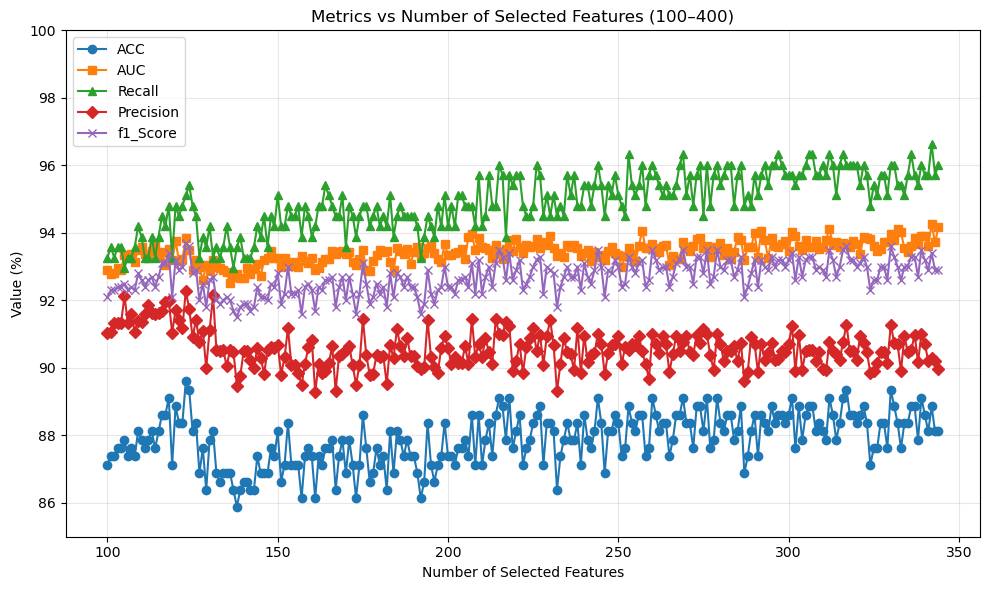

In [ ]:

import ast
import matplotlib.pyplot as plt
import pandas as pd

# -------- settings you can change --------
min_features = 100
max_features = 400

y_min = 85
y_max = 100

# 👉 Select metrics you want to plot
metrics = ["ACC", "AUC", "Recall", "Precision", "f1_Score"]  
# Example:
# metrics = ["ACC", "Recall", "Precision"]
# ----------------------------------------

df_plot = df_result.copy()

# Convert selected metrics from % to float
for m in metrics:
    df_plot[m] = df_plot[m].str.replace("%", "", regex=False).astype(float)

# Count number of selected genes
def count_features(gene_value):
    if isinstance(gene_value, list):
        return len(gene_value)
    try:
        return len(ast.literal_eval(gene_value))
    except:
        return None

df_plot["Num_Features"] = df_plot["Gene"].apply(count_features)

# Filter feature range
df_plot = df_plot[
    (df_plot["Num_Features"] >= min_features) & 
    (df_plot["Num_Features"] <= max_features)
]

# Group by number of features (average values)
df_plot = df_plot.groupby("Num_Features", as_index=False)[metrics].mean()

# Plot
plt.figure(figsize=(10, 6))

markers = ["o", "s", "^", "D", "x", "*"]  # different markers for clarity

for i, m in enumerate(metrics):
    plt.plot(df_plot["Num_Features"], df_plot[m],
             marker=markers[i % len(markers)],
             label=m)

plt.xlabel("Number of Selected Features")
plt.ylabel("Value (%)")
plt.title(f"Metrics vs Number of Selected Features ({min_features}–{max_features})")

plt.ylim(y_min, y_max)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:

save_path = r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs\Siamese_training_11_5.csv"
df_result = pd.read_csv(save_path, low_memory =False)


df_result2 = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs\Siamese_test_11_5.csv", low_memory=False)


In [37]:
df_result

,Gene,ACC,Recall,Precision,Sp,Sn,f1_Score,AUC,Parameter
0,"['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...",80.37%,81.42%,93.40%,76.02%,81.42%,86.98%,86.93%,"{'embed_dim': 32, 'epochs': 30, 'hidden_dim': ..."
1,"['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...",81.49%,82.57%,93.75%,77.00%,82.57%,87.79%,87.26%,"{'embed_dim': 16, 'epochs': 30, 'hidden_dim': ..."
2,"['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...",80.43%,81.19%,93.73%,77.32%,81.19%,86.99%,87.20%,"{'embed_dim': 32, 'epochs': 50, 'hidden_dim': ..."
3,"['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...",81.98%,83.18%,93.80%,77.01%,83.18%,88.15%,87.62%,"{'embed_dim': 32, 'epochs': 30, 'hidden_dim': ..."
4,"['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...",82.79%,83.57%,94.46%,79.55%,83.57%,88.67%,88.84%,"{'embed_dim': 16, 'epochs': 50, 'hidden_dim': ..."
...,...,...,...,...,...,...,...,...,...
193,"['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...",86.81%,88.10%,95.19%,81.47%,88.10%,91.50%,92.52%,"{'embed_dim': 32, 'epochs': 30, 'hidden_dim': ..."
194,"['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...",87.06%,88.40%,95.23%,81.48%,88.40%,91.67%,92.59%,"{'embed_dim': 16, 'epochs': 30, 'hidden_dim': ..."
195,"['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...",86.50%,87.94%,94.98%,80.52%,87.94%,91.31%,92.68%,"{'embed_dim': 16, 'epochs': 30, 'hidden_dim': ..."
196,"['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...",86.81%,88.10%,95.21%,81.49%,88.10%,91.50%,92.78%,"{'embed_dim': 16, 'epochs': 30, 'hidden_dim': ..."


In [ ]:
# df_result.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs\XGB_DEG_TPE.csv", index=False)

In [ ]:
xxx

In [38]:
for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
    df_result[col] = df_result[col].str.rstrip("%").astype(float)

In [39]:
for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
    df_result2[col] = df_result2[col].str.rstrip("%").astype(float)

In [40]:
# 1. Apply the Standard Definition of Balanced Accuracy
df_result['BA'] = (df_result['Sn'] + df_result['Sp']) / 2

In [41]:
# 1. Apply the Standard Definition of Balanced Accuracy
df_result2['BA'] = (df_result2['Sn'] + df_result2['Sp']) / 2

In [42]:
# Use '&' to ensure BOTH conditions are met
sp_threshold = 0
auc_threshold = 0
pre = 0
# This creates a strict filter
mask = (df_result["Sp"] >= sp_threshold) & (df_result["AUC"] >= auc_threshold) & (df_result["Precision"] >= pre)
filtered_df = df_result[mask]

if not filtered_df.empty:
    best_row = filtered_df.loc[filtered_df["BA"].idxmax()]
    print("Best Model Meeting Strict Criteria:")
    print(best_row)
else:
    print(f"No models found with Sp > {sp_threshold} and AUC > {auc_threshold}.")
    # Optional: see what the highest Sp available is
    print(f"Max Sp in data: {df_result['Sp'].max()}")

Best Model Meeting Strict Criteria:
Gene         ['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...
ACC                                                      86.75
Recall                                                   87.48
Precision                                                95.73
Sp                                                       83.71
Sn                                                       87.48
f1_Score                                                  91.4
AUC                                                      92.72
Parameter    {'embed_dim': 32, 'epochs': 30, 'hidden_dim': ...
BA                                                      85.595
Name: 158, dtype: object


In [43]:
df_result2.iloc[158]
# ACC 227 -> acc 89.6
# Recall 231
# Precision 194
# Sp 194
# Sn 231 -> acc 89.36
# AUC 306

Gene         ['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...
ACC                                                      83.91
Recall                                                   84.36
Precision                                                95.16
Sp                                                       82.05
Sn                                                       84.36
f1_Score                                                 89.43
AUC                                                      91.67
Parameter    {'embed_dim': 32, 'epochs': 30, 'hidden_dim': ...
BA                                                      83.205
Name: 158, dtype: object

In [44]:
df_result2.loc[df_result2["BA"].idxmax()]
# ACC 210
# AUC 92.6
# Sp 227
# BA 194

Gene         ['MAGOHB', 'WDR11-DT', 'ZNF542P', 'ITGA2B', 'I...
ACC                                                      84.65
Recall                                                   83.13
Precision                                                97.48
Sp                                                       91.03
Sn                                                       83.13
f1_Score                                                 89.74
AUC                                                      93.09
Parameter    {'embed_dim': 16, 'epochs': 30, 'hidden_dim': ...
BA                                                       87.08
Name: 120, dtype: object

In [ ]:
df_result.loc[df_result["BA"].idxmax()]

Gene         ['ENSG00000111196', 'ENSG00000227165', 'ENSG00...
ACC                                                      86.69
Recall                                                   88.71
Precision                                                94.48
Sp                                                       78.24
Sn                                                       88.71
f1_Score                                                 91.47
AUC                                                      91.68
Parameter    {'colsample_bytree': 0.7, 'learning_rate': 0.0...
BA                                                      83.475
Name: 76, dtype: object

In [ ]:
best_genes = df_result.loc[df_result["BA"].idxmax(), "Gene"]

In [ ]:
# percent_cols = ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]

# for col in percent_cols:
#     df_result[col] = df_result[col].str.rstrip("%").astype(float)

In [ ]:
import ast

# Convert string → list
best_genes = ast.literal_eval(best_genes)

In [ ]:
len(best_genes)

87

In [ ]:
# Select features
X_train = X_train[best_genes]
X_test  = X_test[best_genes]

In [ ]:
X_train

,ENSG00000111196,ENSG00000227165,ENSG00000240225,ENSG00000005961,ENSG00000142089,ENSG00000103512,ENSG00000142856,ENSG00000130948,ENSG00000133742,ENSG00000102265,...,ENSG00000151789,ENSG00000229124,ENSG00000151702,ENSG00000104267,ENSG00000155096,ENSG00000177410,ENSG00000165309,ENSG00000248242,ENSG00000170365,ENSG00000070182
0,5.825938,7.110467,5.597614,12.500856,5.678055,7.015822,6.805345,4.248845,4.181072,9.531509,...,5.658389,5.975242,6.822685,12.175179,6.021632,5.894297,6.962138,5.038464,4.711711,6.865134
1,6.776807,7.286829,6.157093,11.363343,5.260538,6.194023,7.762619,4.531355,5.138988,9.779587,...,6.819600,6.446852,6.585961,11.591065,7.110930,6.523894,6.640120,5.614355,4.504321,6.111449
2,6.249818,6.396065,5.377009,13.356263,6.186774,7.136737,8.324871,3.762020,3.154206,10.366250,...,5.640788,5.119759,6.086539,11.139876,6.528563,6.339376,5.733350,5.434107,3.154206,7.840116
3,5.707795,6.904294,5.581797,13.074632,5.287436,6.227778,8.193052,5.328028,4.130256,9.429653,...,5.929484,5.823110,5.707795,12.451368,7.161602,6.541346,7.003302,6.004212,3.154206,7.442579
4,5.520162,6.875443,6.536687,11.444883,6.403045,6.255406,6.908551,3.154206,3.154206,9.169919,...,5.520162,4.485261,6.875443,11.197625,7.656176,7.148956,6.908551,5.428549,4.485261,5.834695
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1610,3.154206,5.984283,4.459019,12.798538,6.887952,5.291225,6.980355,5.291225,3.154206,10.304355,...,5.563718,5.790092,5.790092,9.930990,6.789147,6.306363,5.563718,4.945690,4.459019,6.682972
1611,3.154206,5.950298,4.920853,12.448855,7.634042,5.532925,8.450585,3.154206,3.154206,10.259736,...,5.950298,3.154206,5.532925,9.476624,4.920853,7.739952,3.154206,3.154206,5.532925,7.634042
1612,6.572820,6.510666,5.089071,12.643616,5.542191,5.879830,7.006262,4.659690,5.147996,10.099275,...,5.542191,5.310044,6.489327,11.060083,7.908163,6.960692,5.204309,5.912678,4.569759,7.050424
1613,4.721758,5.048472,3.154206,12.715898,7.858618,4.602869,4.829465,4.063923,3.154206,10.471898,...,3.154206,4.794654,6.380567,10.169046,6.432983,6.909253,4.515853,4.896171,3.154206,6.818089


# Test set

In [ ]:
import numpy as np
import pandas as pd
import time
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, classification_report, roc_curve, auc
# Preserve true gene names before converting DataFrames to numpy arrays
# --- 1. Subset Selection (87 Genes) ---
X_train = X_train.iloc[:, :87]
X_test = X_test.iloc[:, :87]
gene_names_selected = X_train.columns.tolist()
# --- 2. Scaling ---
scale = StandardScaler()
X_train = scale.fit_transform(X_train)
X_test = scale.transform(X_test)

In [ ]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier # ADDED
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, accuracy_score, roc_curve

# --- 1. Custom Scorers ---
def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        return tn / (tn + fp)
    return 0.0

def balanced_accuracy_medical(y_true, y_pred):
    sn = recall_score(y_true, y_pred, zero_division=0)
    sp = specificity_score(y_true, y_pred)
    return (sn + sp) / 2

scoring_metrics = {
    'ACC': 'accuracy',
    'Recall': 'recall',
    'Precision': 'precision',
    'Sp': make_scorer(specificity_score),
    'Sn': 'recall',
    'f1_Score': 'f1',
    'AUC': 'roc_auc',
    'BA': make_scorer(balanced_accuracy_medical) 
}

# --- 2. Grid Search Setup ---
# Calculate ratio: 391 / 1628 approx 0.24 to handle imbalance
imbalance_ratio = 391 / 1628 

model = XGBClassifier(
    random_state=11, 
    n_jobs=-1, 
    eval_metric='logloss',
    scale_pos_weight=imbalance_ratio # ADDED: Fixes low Specificity
)

params = {
    'n_estimators': [4000],
    'learning_rate': [0.001],
    'subsample': [0.7],
    'colsample_bytree': [0.7],
}

grid_search = GridSearchCV(
    estimator=model, 
    param_grid=params, 
    cv=5, 
    scoring=scoring_metrics, 
    refit='BA', # Selection based on (Sn + Sp) / 2
    n_jobs=-1,
    verbose=2
)

In [ ]:
import time
start_time = time.time()
grid_search.fit(X_train, y_train['cancer_type'])
end_time = time.time()

Fitting 5 folds for each of 1 candidates, totalling 5 fits


In [ ]:
# best_idx = grid_search.best_index_
# cv_res = grid_search.cv_results_
# best_model = grid_search.best_estimator_

# def fmt(metric):
#     return f"{cv_res[f'mean_test_{metric}'][best_idx] * 100:.2f}%"

# # THRESHOLD LOCK LOGIC
# y_prob_train = best_model.predict_proba(X_train)[:, 1]
# fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train['cancer_type'], y_prob_train)

# # Youden's J statistic
# best_threshold = thresholds_tr[np.argmax(tpr_tr - fpr_tr)]
# result = []
# # Append Training Result
# result.append([
#      fmt('ACC'), fmt('Recall'), fmt('Precision'), 
#     fmt('Sp'), fmt('Sn'), fmt('f1_Score'), fmt('AUC'), 
#     grid_search.best_params_
# ])

In [ ]:
# df_result = pd.DataFrame(result, columns=['ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter'])
# df_result
# for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
#     df_result[col] = df_result[col].str.rstrip("%").astype(float)
# # 1. Apply the Standard Definition of Balanced Accuracy
# df_result['BA'] = (df_result['Sn'] + df_result['Sp']) / 2
# y_prob = best_model.predict_proba(X_test)[:, 1]
# y_pred = (y_prob >= best_threshold).astype(int)

In [ ]:
best_idx = grid_search.best_index_
a = grid_search.cv_results_['mean_test_AUC'][best_idx]
a

np.float64(0.916810334641258)

In [ ]:
import pandas as pd
import numpy as np

# Lấy kết quả từ GridSearch
results = grid_search.cv_results_

# Tạo DataFrame
df_results = pd.DataFrame(results)

# --- THE FIX: Add '_BA' to the metric columns ---

# Tính phương sai từ std của metric BA
df_results['var_test_BA'] = df_results['std_test_BA'] ** 2

# Chọn các cột quan trọng
summary_table = df_results[[
    'params',
    'mean_test_BA',   # Replaced 'mean_test_score'
    'std_test_BA',    # Replaced 'std_test_score'
    'var_test_BA',    # Replaced 'var_test_score'
    'rank_test_BA'    # Replaced 'rank_test_score'
]]

# Sắp xếp theo mean_test_BA giảm dần
summary_table = summary_table.sort_values(by='mean_test_BA', ascending=False)

print(summary_table.head(10))

                                              params  mean_test_BA  \
0  {'colsample_bytree': 0.7, 'learning_rate': 0.0...      0.834766   

   std_test_BA  var_test_BA  rank_test_BA  
0      0.03102     0.000962             1  


In [ ]:
summary_table.head(10)

,params,mean_test_BA,std_test_BA,var_test_BA,rank_test_BA
0,"{'colsample_bytree': 0.7, 'learning_rate': 0.0...",0.834766,0.03102,0.000962,1


In [ ]:
best_params = grid_search.best_params_

In [ ]:
best_accuracy = grid_search.best_score_

In [ ]:
best_params

{'colsample_bytree': 0.7,
 'learning_rate': 0.001,
 'n_estimators': 4000,
 'subsample': 0.7}

In [ ]:
best_accuracy

np.float64(0.83476564653984)

In [ ]:
# Calculate training time
training_time = end_time - start_time

In [ ]:
y_pred = grid_search.predict(X_test)

In [ ]:
from sklearn.metrics import classification_report

# Reslut for testing set

In [ ]:
from sklearn.metrics import roc_curve, auc

In [ ]:


# print("Training time:", training_time, "seconds")
print(classification_report( y_test['cancer_type'],y_pred,digits=6))


              precision    recall  f1-score   support

           0   0.593407  0.692308  0.639053        78
           1   0.923323  0.886503  0.904538       326

    accuracy                       0.849010       404
   macro avg   0.758365  0.789405  0.771796       404
weighted avg   0.859626  0.849010  0.853281       404



### Plot Figure

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sn

Text(113.9222222222222, 0.5, 'Predicted Values')

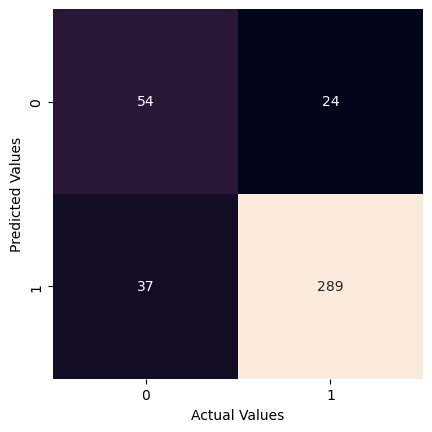

In [ ]:
mat_imp = confusion_matrix(y_test['cancer_type'],y_pred)
sn.heatmap(mat_imp,square=True, annot=True, fmt='d', cbar=False)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

In [ ]:
from sklearn.metrics import roc_curve, auc
y_scores = grid_search.predict_proba(X_test)
fpr, tpr, thresholds = roc_curve(y_test['cancer_type'], y_scores[:, 1])
roc_auc = auc(fpr, tpr)
roc_auc

0.9059697970740915

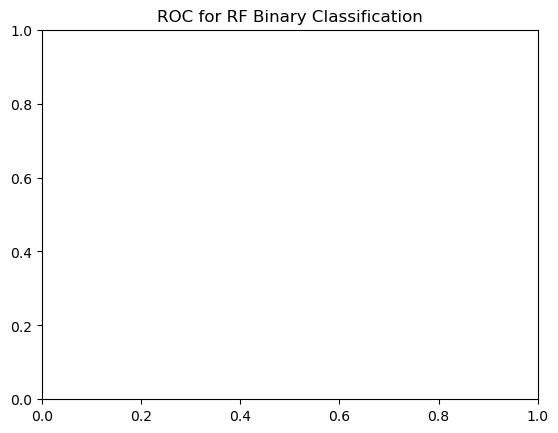

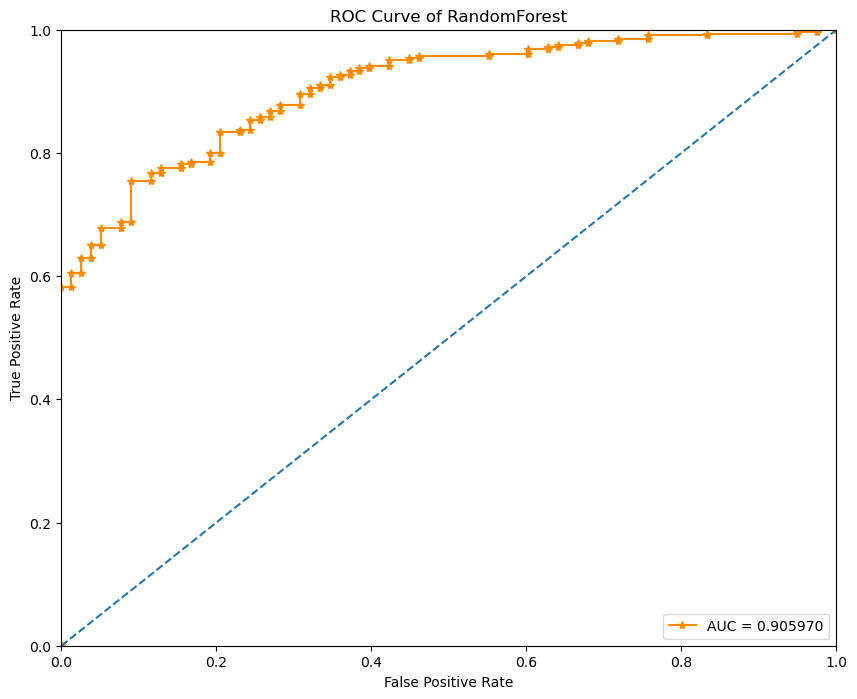

In [ ]:
plt.title('ROC for RF Binary Classification')
plt.figure(figsize=(10,8))
plt.plot(fpr,tpr, marker = '*',color='darkorange',label = 'AUC = %0.6f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('ROC Curve of RandomForest')
plt.show()

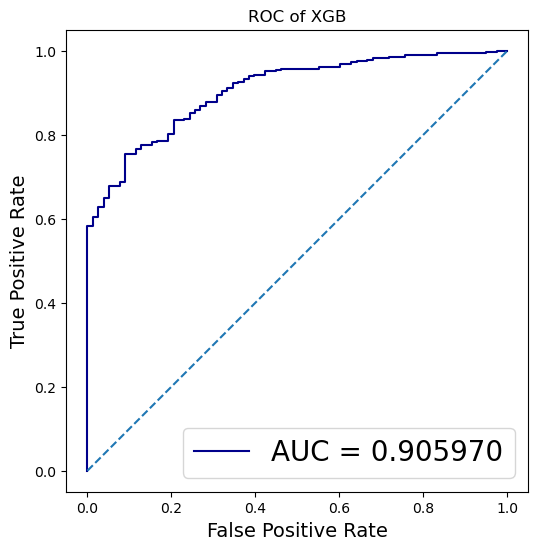

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.title('ROC of XGB')
plt.plot(fpr, tpr, color='darkblue', label='AUC = %0.6f' % roc_auc)
plt.legend(loc='lower right', fontsize=20)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.axis('scaled')
plt.ylabel('True Positive Rate', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=14)
plt.show()


# Shap

In [ ]:
# SHAP prerequisites check
if 'grid_search' not in locals():
    raise RuntimeError('grid_search is not defined. Run the model training cells before SHAP.')

In [ ]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# --- 1) Prepare model and SHAP-ready data ---
best_estimator = grid_search.best_estimator_
print(f"Best estimator type: {type(best_estimator).__name__}")

# Recover feature names with priority:
# 1) Saved names before scaling, 2) DataFrame columns, 3) best_genes, 4) fallback labels
if 'gene_names_selected' in locals() and len(gene_names_selected) == np.asarray(X_train).shape[1]:
    feature_names = list(gene_names_selected)
elif isinstance(X_train, pd.DataFrame):
    feature_names = X_train.columns.tolist()
elif 'best_genes' in locals() and len(best_genes) >= np.asarray(X_train).shape[1]:
    feature_names = list(best_genes[:np.asarray(X_train).shape[1]])
else:
    feature_names = [f"Gene_{i}" for i in range(np.asarray(X_train).shape[1])]

X_train_shap = pd.DataFrame(np.asarray(X_train), columns=feature_names)
X_test_shap = pd.DataFrame(np.asarray(X_test), columns=feature_names)

# Use a subset for speed/stability with KernelExplainer
n_background = min(100, len(X_train_shap))
n_explain = min(80, len(X_test_shap))
background = shap.sample(X_train_shap, n_background, random_state=42)
X_explain = shap.sample(X_test_shap, n_explain, random_state=42)

# --- 2) Build SHAP explainer ---
# For SVC with non-linear kernels, KernelExplainer is the most robust choice.
def predict_pos_class(data):
    return best_estimator.predict_proba(data)[:, 1]

explainer = shap.KernelExplainer(predict_pos_class, background)
print("Calculating SHAP values... (this can take a while)")
shap_values = explainer.shap_values(X_explain, nsamples=200)

# Handle SHAP output shape across versions
if isinstance(shap_values, list):
    # Older SHAP can return [class0, class1]
    shap_matrix = np.asarray(shap_values[1])
else:
    shap_matrix = np.asarray(shap_values)
    if shap_matrix.ndim == 3:
        # (samples, features, classes) -> positive class
        shap_matrix = shap_matrix[:, :, 1]

print("SHAP matrix shape:", shap_matrix.shape)

Best estimator type: XGBClassifier
Calculating SHAP values... (this can take a while)


  0%|          | 0/80 [00:00<?, ?it/s]

SHAP matrix shape: (80, 87)


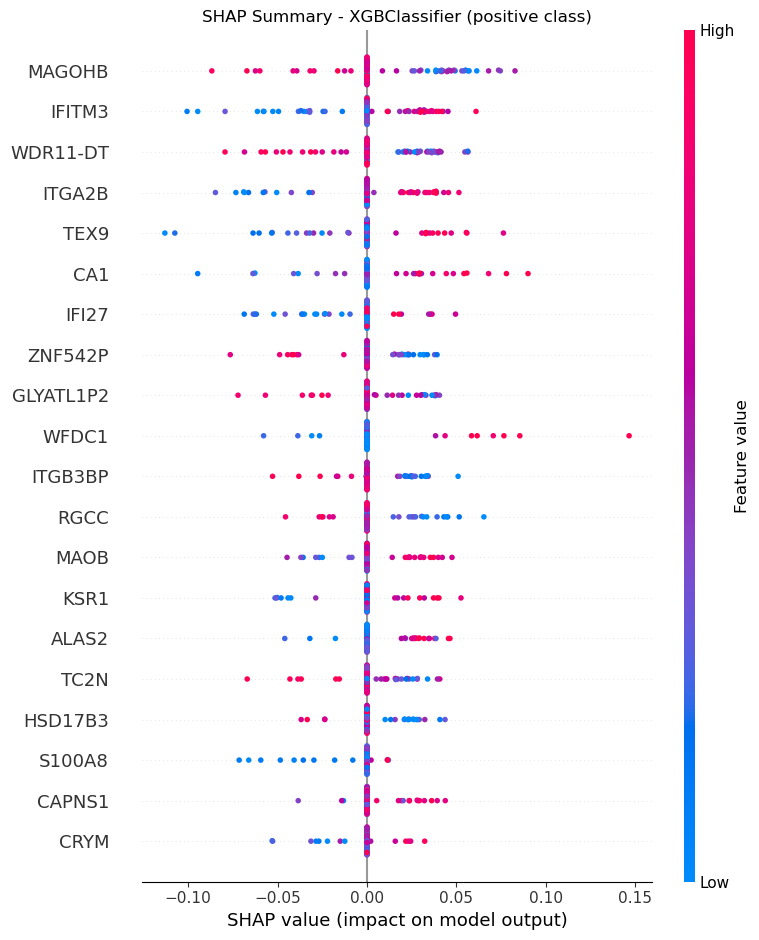

Top 10 Gene Biomarkers:
         Gene  SHAP_Abs_Mean
0      MAGOHB       0.022828
4      IFITM3       0.020612
1    WDR11-DT       0.019500
3      ITGA2B       0.017084
27       TEX9       0.015406
8         CA1       0.013040
17      IFI27       0.010241
2     ZNF542P       0.009877
37  GLYATL1P2       0.009401
25      WFDC1       0.009189


In [ ]:
# --- 3) Plot SHAP summary ---
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_matrix,
    features=X_explain,
    feature_names=feature_names,
    show=False
)
plt.title(f"SHAP Summary - {type(best_estimator).__name__} (positive class)")
plt.tight_layout()
plot_name = f"shap_summary_{type(best_estimator).__name__}.png"
# plt.savefig(plot_name, bbox_inches='tight', dpi=300)
plt.show()

# --- 4) Export ranked biomarkers ---
mean_abs_shap = np.abs(shap_matrix).mean(axis=0)
importance_df = pd.DataFrame({
    'Gene': feature_names,
    'SHAP_Abs_Mean': mean_abs_shap
}).sort_values(by='SHAP_Abs_Mean', ascending=False)

print("Top 10 Gene Biomarkers:")
print(importance_df.head(10))


In [ ]:

importance_df.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\SHAP_xgb.csv", index=False)
print(f"Saved SHAP plot to: {plot_name}")

Saved SHAP plot to: shap_summary_XGBClassifier.png
